# 🦷 Dental Disease Detection — YOLOv8 Training on Kaggle
**Classes:** calculus | cancer | caries | gingivitis | ulcer
**Dataset:** `oral_dataset_balanced` — Train: 3797 | Valid: 696 | Test: 503 images (~160 MB)

The dataset was rebuilt (see `Action.md`) to be **class-balanced and leakage-free**:
- no source photo (or near-duplicate of it) appears in more than one split,
- images per class are capped and *boxes per class* are balanced to within ~2 : 1,
- small enough for the Kaggle free tier (single T4/P100, ~1–2 h for 100 epochs with YOLOv8s).

---
### 📋 Steps in this notebook:
1. Setup environment & install dependencies
2. Load the dataset (Kaggle Dataset input — recommended — or download the zip)
3. Analyze dataset structure, class balance & verify there is no split leakage
4. Write `data.yaml` for Kaggle
5. Visualize sample images & class distribution
6. Train YOLOv8 model
7. Evaluate on validation & test set
8. Run predictions with visualization
9. Export & save best model (download `best.pt` and replace `best.pt` in the project root)

## ✅ Step 1: Setup — Install Dependencies

In [8]:
# Install ultralytics (YOLOv8)
!pip install ultralytics --quiet
!pip install Pillow matplotlib seaborn --quiet

import os, shutil, yaml, glob, random
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from pathlib import Path
from collections import Counter
import seaborn as sns

from ultralytics import YOLO
import torch

print(f"PyTorch version : {torch.__version__}")
print(f"CUDA available  : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU             : {torch.cuda.get_device_name(0)}")
    print(f"VRAM            : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

# ── GPU ONLY: stop immediately instead of silently training on CPU
assert torch.cuda.is_available(), (
    "No GPU found! Kaggle: Settings -> Accelerator -> GPU T4 x2 (or P100), then re-run.")
DEVICE = 0     # first CUDA GPU; used by train / val / predict below

PyTorch version : 2.11.0+cu128
CUDA available  : True
GPU             : Tesla T4
VRAM            : 15.6 GB


## ✅ Step 2: Load the Dataset

**Recommended (fastest, no re-download):** upload `oral_dataset_balanced.zip` as a *Kaggle Dataset*
(Kaggle → Datasets → New Dataset), then in this notebook click **Add Input** and add it.
The next cell finds it automatically under `/kaggle/input`.

**Fallback:** put the zip on Google Drive and set `FILE_ID` below.

In [9]:
import os, zipfile, glob

WORK        = "/kaggle/working"
FILE_ID     = ""     # only needed if you are NOT adding the dataset as a Kaggle input

def has_splits(d):
    return all(os.path.isdir(os.path.join(d, s, "images")) for s in ("train", "valid", "test"))

# 1) Kaggle input (read-only, instant) — also unzips if the raw zip was uploaded
DATASET_ROOT = None
for root, dirs, files in os.walk("/kaggle/input"):
    if has_splits(root):
        DATASET_ROOT = root; break
    for f in files:
        if f.endswith(".zip") and "oral" in f.lower():
            print("📦 Extracting", f)
            with zipfile.ZipFile(os.path.join(root, f)) as z: z.extractall(WORK)
            break
# 2) Already extracted into /kaggle/working
if DATASET_ROOT is None:
    for root, dirs, files in os.walk(WORK):
        if has_splits(root):
            DATASET_ROOT = root; break
# 3) Download from Google Drive
if DATASET_ROOT is None:
    assert FILE_ID, "Add the dataset as a Kaggle input, or set FILE_ID."
    !pip install -q gdown
    import gdown
    zp = f"{WORK}/oral_dataset_balanced.zip"
    gdown.download(f"https://drive.google.com/uc?id={FILE_ID}", zp, quiet=False)
    with zipfile.ZipFile(zp) as z: z.extractall(WORK)
    DATASET_ROOT = next(r for r, _, _ in os.walk(WORK) if has_splits(r))

# /kaggle/input is a slow (~1 MB/s), read-only network mount -> 'Slow image access' warnings and no
# label cache. The dataset is only ~160 MB, so copy it to local disk once (takes ~2-4 min).
# Copy into a temp folder and rename at the end, so an interrupted copy is never mistaken for a full one.
import shutil, time
if DATASET_ROOT.startswith("/kaggle/input"):
    LOCAL_ROOT = f"{WORK}/oral_dataset_balanced"
    if not has_splits(LOCAL_ROOT):
        TMP_ROOT = LOCAL_ROOT + "_tmp"
        shutil.rmtree(TMP_ROOT, ignore_errors=True)
        shutil.rmtree(LOCAL_ROOT, ignore_errors=True)
        print("📋 Copying dataset to local disk (be patient, network mount is slow)...")
        t0 = time.time()
        shutil.copytree(DATASET_ROOT, TMP_ROOT)
        os.rename(TMP_ROOT, LOCAL_ROOT)
        print(f"   done in {time.time() - t0:.0f}s")
    DATASET_ROOT = LOCAL_ROOT

PLOTS_DIR = f"{WORK}/plots"; os.makedirs(PLOTS_DIR, exist_ok=True)
print("✅ Dataset root:", DATASET_ROOT)

📋 Copying dataset to local disk (be patient, network mount is slow)...
   done in 192s
✅ Dataset root: /kaggle/working/oral_dataset_balanced


## ✅ Step 3: Analyze Dataset Structure, Balance & Leakage

In [10]:
# Verify split structure (DATASET_ROOT was located in Step 2)
import re
splits = ['train', 'valid', 'test']
CLASS_NAMES = ['calculus', 'cancer', 'caries', 'gingivitis', 'ulcer']
NUM_CLASSES  = len(CLASS_NAMES)

print(f"📂 Dataset root: {DATASET_ROOT}\n")
print("📊 Dataset Structure:")
print("-" * 55)
total_images = 0
total_labels = 0

split_info = {}
for split in splits:
    img_dir = os.path.join(DATASET_ROOT, split, 'images')
    lbl_dir = os.path.join(DATASET_ROOT, split, 'labels')

    imgs = glob.glob(os.path.join(img_dir, '*.jpg')) + \
           glob.glob(os.path.join(img_dir, '*.jpeg')) + \
           glob.glob(os.path.join(img_dir, '*.png'))
    lbls = glob.glob(os.path.join(lbl_dir, '*.txt')) if os.path.exists(lbl_dir) else []

    split_info[split] = {'images': len(imgs), 'labels': len(lbls), 'img_dir': img_dir, 'lbl_dir': lbl_dir}
    total_images += len(imgs)
    total_labels += len(lbls)

    img_status = '✅' if os.path.exists(img_dir) else '❌'
    lbl_status = '✅' if os.path.exists(lbl_dir) else '❌'
    print(f"  {split:<8} | images: {img_status} {len(imgs):>5} | labels: {lbl_status} {len(lbls):>5}")

print("-" * 55)
print(f"  {'TOTAL':<8} | images:    {total_images:>5} | labels:    {total_labels:>5}")

# ── Leakage check: the same source photo must never be in two splits
def source_ids(split):
    return {re.sub(r'_(jpg|jpeg|png)\.rf\..*$', '', os.path.basename(f))
            for f in glob.glob(os.path.join(split_info[split]['img_dir'], '*'))}
sids = {s: source_ids(s) for s in splits}
overlap = {f"{a}/{b}": len(sids[a] & sids[b]) for i, a in enumerate(splits) for b in splits[i+1:]}
print("\n🔒 Source-photo overlap between splits (must be 0):", overlap)
assert all(v == 0 for v in overlap.values()), "Data leakage detected!"

📂 Dataset root: /kaggle/working/oral_dataset_balanced

📊 Dataset Structure:
-------------------------------------------------------
  train    | images: ✅  3797 | labels: ✅  3797
  valid    | images: ✅   696 | labels: ✅   696
  test     | images: ✅   503 | labels: ✅   503
-------------------------------------------------------
  TOTAL    | images:     4996 | labels:     4996

🔒 Source-photo overlap between splits (must be 0): {'train/valid': 0, 'train/test': 0, 'valid/test': 0}


In [11]:
# Count class distribution across splits (boxes = annotations, images = images containing the class)
def count_classes(label_dir):
    boxes, imgs = Counter(), Counter()
    for lf in glob.glob(os.path.join(label_dir, '*.txt')):
        seen = set()
        with open(lf) as f:
            for line in f:
                line = line.strip()
                if line:
                    cls = int(line.split()[0]); boxes[cls] += 1; seen.add(cls)
        for c in seen: imgs[c] += 1
    return boxes, imgs

all_counts, all_img_counts = {}, {}
for split in splits:
    all_counts[split], all_img_counts[split] = count_classes(split_info[split]['lbl_dir'])

print("\n📊 Class Distribution (boxes / images) per Split:")
print("-" * 80)
print(f"  {'Class':<12}" + "".join(f"  {s:>14}" for s in splits) + "   Total boxes")
print("-" * 80)
for i, name in enumerate(CLASS_NAMES):
    row, total = f"  {name:<12}", 0
    for split in splits:
        b, im = all_counts[split].get(i, 0), all_img_counts[split].get(i, 0)
        total += b
        row += f"  {f'{b} / {im}':>14}"
    print(row + f"   {total}")
print("-" * 80)
tb = [all_counts['train'].get(i, 0) for i in range(NUM_CLASSES)]
print(f"Train box imbalance (max/min): {max(tb)/max(min(tb),1):.2f} : 1   (original dataset was ~6.1 : 1)")


📊 Class Distribution (boxes / images) per Split:
--------------------------------------------------------------------------------
  Class                  train           valid            test   Total boxes
--------------------------------------------------------------------------------
  calculus          3003 / 409        556 / 80        397 / 58   3956
  cancer           1523 / 1000       269 / 184       199 / 131   1991
  caries           2785 / 1000       499 / 184       362 / 131   3646
  gingivitis        3004 / 388        554 / 64        398 / 52   3956
  ulcer            1553 / 1000       289 / 184       211 / 131   2053
--------------------------------------------------------------------------------
Train box imbalance (max/min): 1.97 : 1   (original dataset was ~6.1 : 1)


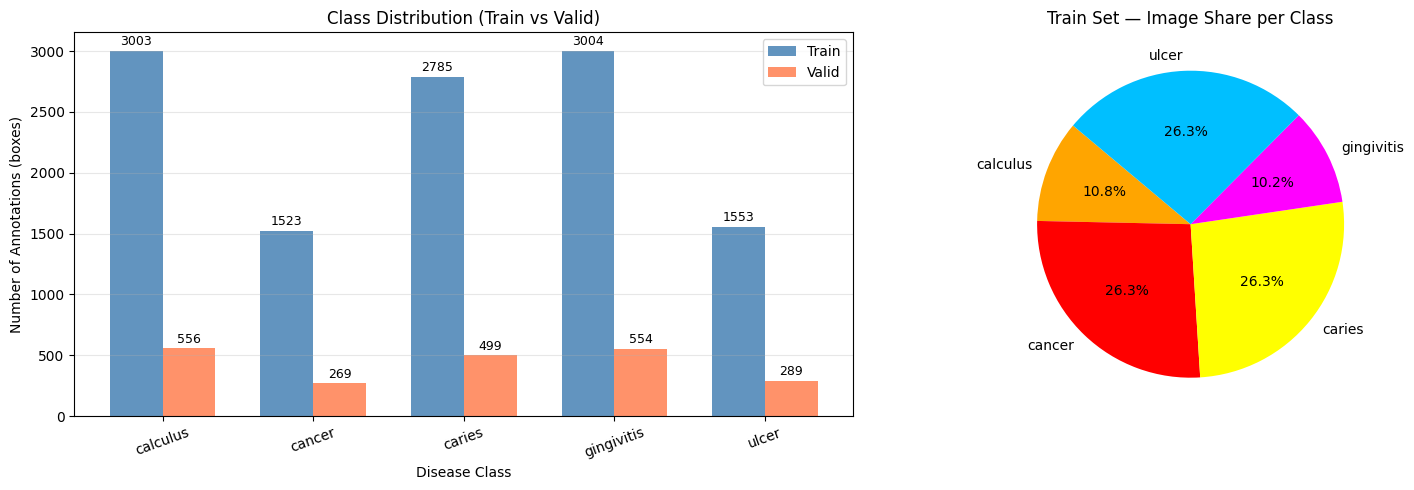

In [12]:
# Visualize class distribution
train_counts = [all_counts['train'].get(i, 0) for i in range(NUM_CLASSES)]
valid_counts = [all_counts['valid'].get(i, 0) for i in range(NUM_CLASSES)]

x = np.arange(NUM_CLASSES)
width = 0.35

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

ax = axes[0]
bars1 = ax.bar(x - width/2, train_counts, width, label='Train', color='steelblue', alpha=0.85)
bars2 = ax.bar(x + width/2, valid_counts, width, label='Valid', color='coral',     alpha=0.85)
ax.set_xlabel('Disease Class')
ax.set_ylabel('Number of Annotations (boxes)')
ax.set_title('Class Distribution (Train vs Valid)')
ax.set_xticks(x)
ax.set_xticklabels(CLASS_NAMES, rotation=20)
ax.legend()
ax.bar_label(bars1, padding=2, fontsize=9)
ax.bar_label(bars2, padding=2, fontsize=9)
ax.grid(axis='y', alpha=0.3)

ax2 = axes[1]
train_imgs = [all_img_counts['train'].get(i, 0) for i in range(NUM_CLASSES)]
ax2.pie(train_imgs, labels=CLASS_NAMES, autopct='%1.1f%%',
        colors=['#FFA500', '#FF0000', '#FFFF00', '#FF00FF', '#00BFFF'], startangle=140)
ax2.set_title('Train Set — Image Share per Class')

plt.tight_layout()
plt.savefig(f'{PLOTS_DIR}/class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

## ✅ Step 4: Create Kaggle-Compatible `data.yaml`

In [13]:
YAML_PATH = f'{WORK}/data.yaml'     # /kaggle/input is read-only, so write the yaml to /kaggle/working

data_yaml = {
    'path' : DATASET_ROOT,
    'train': os.path.join(DATASET_ROOT, 'train', 'images'),
    'val'  : os.path.join(DATASET_ROOT, 'valid', 'images'),
    'test' : os.path.join(DATASET_ROOT, 'test',  'images'),
    'nc'   : NUM_CLASSES,
    'names': CLASS_NAMES
}

with open(YAML_PATH, 'w') as f:
    yaml.dump(data_yaml, f, default_flow_style=False, sort_keys=False)

print("✅ data.yaml written to:", YAML_PATH)
with open(YAML_PATH) as f:
    print(f.read())

✅ data.yaml written to: /kaggle/working/data.yaml
path: /kaggle/working/oral_dataset_balanced
train: /kaggle/working/oral_dataset_balanced/train/images
val: /kaggle/working/oral_dataset_balanced/valid/images
test: /kaggle/working/oral_dataset_balanced/test/images
nc: 5
names:
- calculus
- cancer
- caries
- gingivitis
- ulcer



## ✅ Step 5: Visualize Sample Images with Bounding Boxes

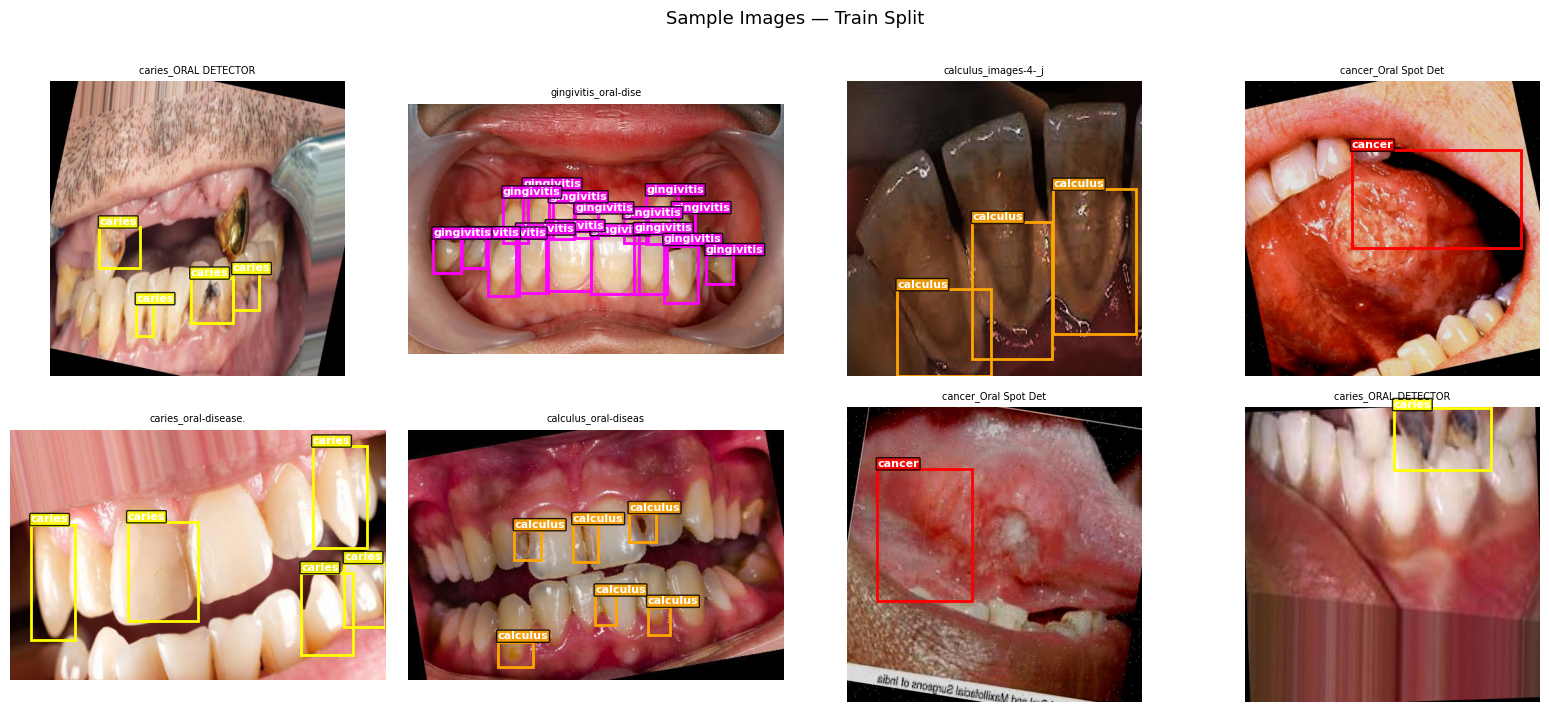

In [14]:
def yolo_to_pixel(box, w, h):
    """Convert YOLO [cx, cy, bw, bh] (normalized) → [x1, y1, x2, y2] (pixel)."""
    cx, cy, bw, bh = box
    x1 = (cx - bw / 2) * w
    y1 = (cy - bh / 2) * h
    x2 = (cx + bw / 2) * w
    y2 = (cy + bh / 2) * h
    return x1, y1, x2 - x1, y2 - y1   # x, y, width, height

# Same colours as the web app: calculus orange, cancer red, caries yellow, gingivitis magenta, ulcer sky blue
COLORS = ['#FFA500','#FF0000','#FFFF00','#FF00FF','#00BFFF']

def show_samples(split='train', n=8):
    img_dir = split_info[split]['img_dir']
    lbl_dir = split_info[split]['lbl_dir']
    imgs = glob.glob(os.path.join(img_dir, '*.jpg')) + \
           glob.glob(os.path.join(img_dir, '*.jpeg')) + \
           glob.glob(os.path.join(img_dir, '*.png'))
    random.shuffle(imgs)
    imgs = imgs[:n]

    cols = 4
    rows = (n + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 4, rows * 3.5))
    axes = axes.flatten()

    for i, img_path in enumerate(imgs):
        img = Image.open(img_path).convert('RGB')
        W, H = img.size
        ax = axes[i]
        ax.imshow(img)

        # Load corresponding label
        stem = Path(img_path).stem
        lbl_path = os.path.join(lbl_dir, stem + '.txt')
        if os.path.exists(lbl_path):
            with open(lbl_path) as f:
                for line in f:
                    parts = line.strip().split()
                    if not parts:
                        continue
                    cls = int(parts[0])
                    box = list(map(float, parts[1:5]))
                    x, y, bw, bh = yolo_to_pixel(box, W, H)
                    rect = patches.Rectangle(
                        (x, y), bw, bh,
                        linewidth=2, edgecolor=COLORS[cls % len(COLORS)], facecolor='none'
                    )
                    ax.add_patch(rect)
                    ax.text(x, max(y - 4, 0), CLASS_NAMES[cls],
                            color='white', fontsize=8, weight='bold',
                            bbox=dict(boxstyle='round,pad=0.1', fc=COLORS[cls % len(COLORS)], alpha=0.85))

        ax.axis('off')
        ax.set_title(stem[:20], fontsize=7)

    for j in range(len(imgs), len(axes)):
        axes[j].axis('off')

    plt.suptitle(f'Sample Images — {split.capitalize()} Split', fontsize=13, y=1.01)
    plt.tight_layout()
    plt.savefig(f'{PLOTS_DIR}/samples_{split}.png', dpi=120, bbox_inches='tight')
    plt.show()

show_samples('train', n=8)

## ✅ Step 6: Train YOLOv8 Model

> 💡 **Kaggle free-tier guide** (T4 ≈ 16 GB, 12 h session limit, 30 GPU h/week):
> - `yolov8s.pt` → recommended default (~1–2 h for 100 epochs on this dataset)
> - `yolov8m.pt` → better accuracy, roughly 2× the time (`BATCH_SIZE = 16`, reduce to 8 on OOM)
> - `yolov8n.pt` → quick smoke test (set `EPOCHS = 5` first to verify the pipeline)
>
> Enable **Settings → Accelerator → GPU T4 x2 / P100** before running. Training uses a single GPU on purpose (multi-GPU DDP is flaky in notebooks).

In [15]:
# ─────────────────────────────────────────────────────────
# 🔧 TRAINING CONFIGURATION — Adjust as needed
# ─────────────────────────────────────────────────────────
MODEL_VARIANT = 'yolov8s.pt'   # options: yolov8n/s/m/l/x.pt
EPOCHS        = 100
IMG_SIZE      = 640
BATCH_SIZE    = 16             # reduce to 8 if GPU OOM
PATIENCE      = 25             # early stopping patience
PROJECT_NAME  = 'dental_yolo'
RUN_NAME      = 'yolov8s_balanced_v2'
# ─────────────────────────────────────────────────────────

model = YOLO(MODEL_VARIANT)
print(f"✅ Loaded model: {MODEL_VARIANT}")
print(f"   Parameters  : {sum(p.numel() for p in model.model.parameters()):,}")

✅ Loaded model: yolov8s.pt
   Parameters  : 11,166,560


In [16]:
# ─── TRAIN ───────────────────────────────────────────────
results = model.train(
    data        = YAML_PATH,
    epochs      = EPOCHS,
    imgsz       = IMG_SIZE,
    batch       = BATCH_SIZE,
    patience    = PATIENCE,
    project     = f'{WORK}/oral_runs',
    name        = RUN_NAME,
    device      = DEVICE,   # GPU only
    workers     = 2,            # Kaggle gives 4 CPU cores
    cache       = 'ram',        # ~2.7 GB RAM, fine on Kaggle (29 GB); data is now on local disk
    amp         = True,
    seed        = 42,
    optimizer   = 'AdamW',
    lr0         = 0.001,
    lrf         = 0.01,
    cos_lr      = True,
    momentum    = 0.937,
    weight_decay= 0.0005,
    warmup_epochs=3,
    close_mosaic= 15,           # last 15 epochs without mosaic -> cleaner box fit
    # Augmentation (dataset is small, so lean on augmentation)
    hsv_h       = 0.015,
    hsv_s       = 0.7,
    hsv_v       = 0.4,
    degrees     = 15.0,
    translate   = 0.1,
    scale       = 0.5,
    fliplr      = 0.5,
    mosaic      = 1.0,
    mixup       = 0.1,
    # Logging
    plots       = True,
    save        = True,
    save_period = -1,           # only best.pt / last.pt (saves /kaggle/working space)
    verbose     = True,
)

print("\n✅ Training complete!")
TRAIN_DIR = results.save_dir
print(f"   Results saved to: {TRAIN_DIR}")

Ultralytics 8.4.190 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=15, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/data.yaml, degrees=15.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.1, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8s_balanced_v2, nbs=64, nms=None, opset=None, optimize=Fal

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


      2/100      5.05G      2.033      2.568      1.959         31        640: 100% ━━━━━━━━━━━━ 238/238 6.0it/s 39.9s0.3ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 22/22 4.8it/s 4.6s0.2s
                   all        696       2167      0.233      0.315      0.234     0.0853

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      3/100      5.05G      2.008      2.481      1.926         37        640: 100% ━━━━━━━━━━━━ 238/238 5.8it/s 41.3s0.4ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 22/22 4.8it/s 4.6s0.2s
                   all        696       2167      0.422      0.316      0.232     0.0945

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      4/100      5.05G      1.969      2.395      1.902         21        640: 100% ━━━━━━━━━━━━ 238/238 5.8it/s 41.1s0.3ss
                 Class     Ima

## ✅ Step 7: Evaluate on Validation & Test Sets

In [17]:
# Load best weights
BEST_WEIGHTS = os.path.join(TRAIN_DIR, 'weights', 'best.pt')
print(f"Loading best weights: {BEST_WEIGHTS}")
best_model = YOLO(BEST_WEIGHTS)

# ── Validation set metrics
print("\n📊 Evaluating on Validation Set...")
val_results = best_model.val(
    data    = YAML_PATH,
    split   = 'val',
    imgsz   = IMG_SIZE,
    batch   = BATCH_SIZE,
    device  = DEVICE,
    verbose = True,
    plots   = True,
)

print("\n✅ Validation Metrics:")
print(f"   mAP50       : {val_results.box.map50:.4f}")
print(f"   mAP50-95    : {val_results.box.map:.4f}")
print(f"   Precision   : {val_results.box.mp:.4f}")
print(f"   Recall      : {val_results.box.mr:.4f}")

Loading best weights: /kaggle/working/oral_runs/yolov8s_balanced_v2/weights/best.pt

📊 Evaluating on Validation Set...
Ultralytics 8.4.190 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 72 layers, 11,127,519 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 800.2±285.8 MB/s, size: 40.1 KB)
val: Scanning /kaggle/working/oral_dataset_balanced/valid/labels.cache... 696 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 696/696 208.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 44/44 4.9it/s 9.0s0.2s
                   all        696       2167       0.53       0.59      0.543      0.251
              calculus         80        556      0.457      0.631      0.515       0.23
                cancer        184        269      0.394      0.152      0.193     0.0593
                caries        184        499      0.462      0.653      0.559   

In [18]:
# ── Test set metrics
print("\n📊 Evaluating on Test Set...")
test_results = best_model.val(
    data    = YAML_PATH,
    split   = 'test',
    imgsz   = IMG_SIZE,
    batch   = BATCH_SIZE,
    device  = DEVICE,
    verbose = True,
    plots   = True,
)

print("\n✅ Test Set Metrics:")
print(f"   mAP50       : {test_results.box.map50:.4f}")
print(f"   mAP50-95    : {test_results.box.map:.4f}")
print(f"   Precision   : {test_results.box.mp:.4f}")
print(f"   Recall      : {test_results.box.mr:.4f}")


📊 Evaluating on Test Set...
Ultralytics 8.4.190 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 72 layers, 11,127,519 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1114.7±448.0 MB/s, size: 43.0 KB)
val: Scanning /kaggle/working/oral_dataset_balanced/test/labels... 503 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 503/503 1.1Kit/s 0.5s<0.1s
val: New cache created: /kaggle/working/oral_dataset_balanced/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 32/32 4.7it/s 6.8s0.2s
                   all        503       1567      0.514      0.583      0.568      0.267
              calculus         58        397      0.449      0.705      0.619      0.295
                cancer        131        199      0.272      0.116      0.155     0.0441
                caries        131        362      0.515      0.696      0.646      0.294
    

In [19]:
# ── Per-class AP table
print("\n📊 Per-Class Metrics (Validation):")
print("-" * 55)
print(f"  {'Class':<15}  {'AP50':>8}  {'AP50-95':>9}")
print("-" * 55)

try:
    maps = val_results.box.maps        # per-class mAP50-95
    ap50s = val_results.box.ap50       # per-class AP50
    for i, name in enumerate(CLASS_NAMES):
        print(f"  {name:<15}  {ap50s[i]:>8.4f}  {maps[i]:>9.4f}")
except Exception as e:
    print(f"  (per-class detail unavailable: {e})")
print("-" * 55)


📊 Per-Class Metrics (Validation):
-------------------------------------------------------
  Class                AP50    AP50-95
-------------------------------------------------------
  calculus           0.5150     0.2303
  cancer             0.1930     0.0593
  caries             0.5585     0.2341
  gingivitis         0.5060     0.2414
  ulcer              0.9415     0.4921
-------------------------------------------------------


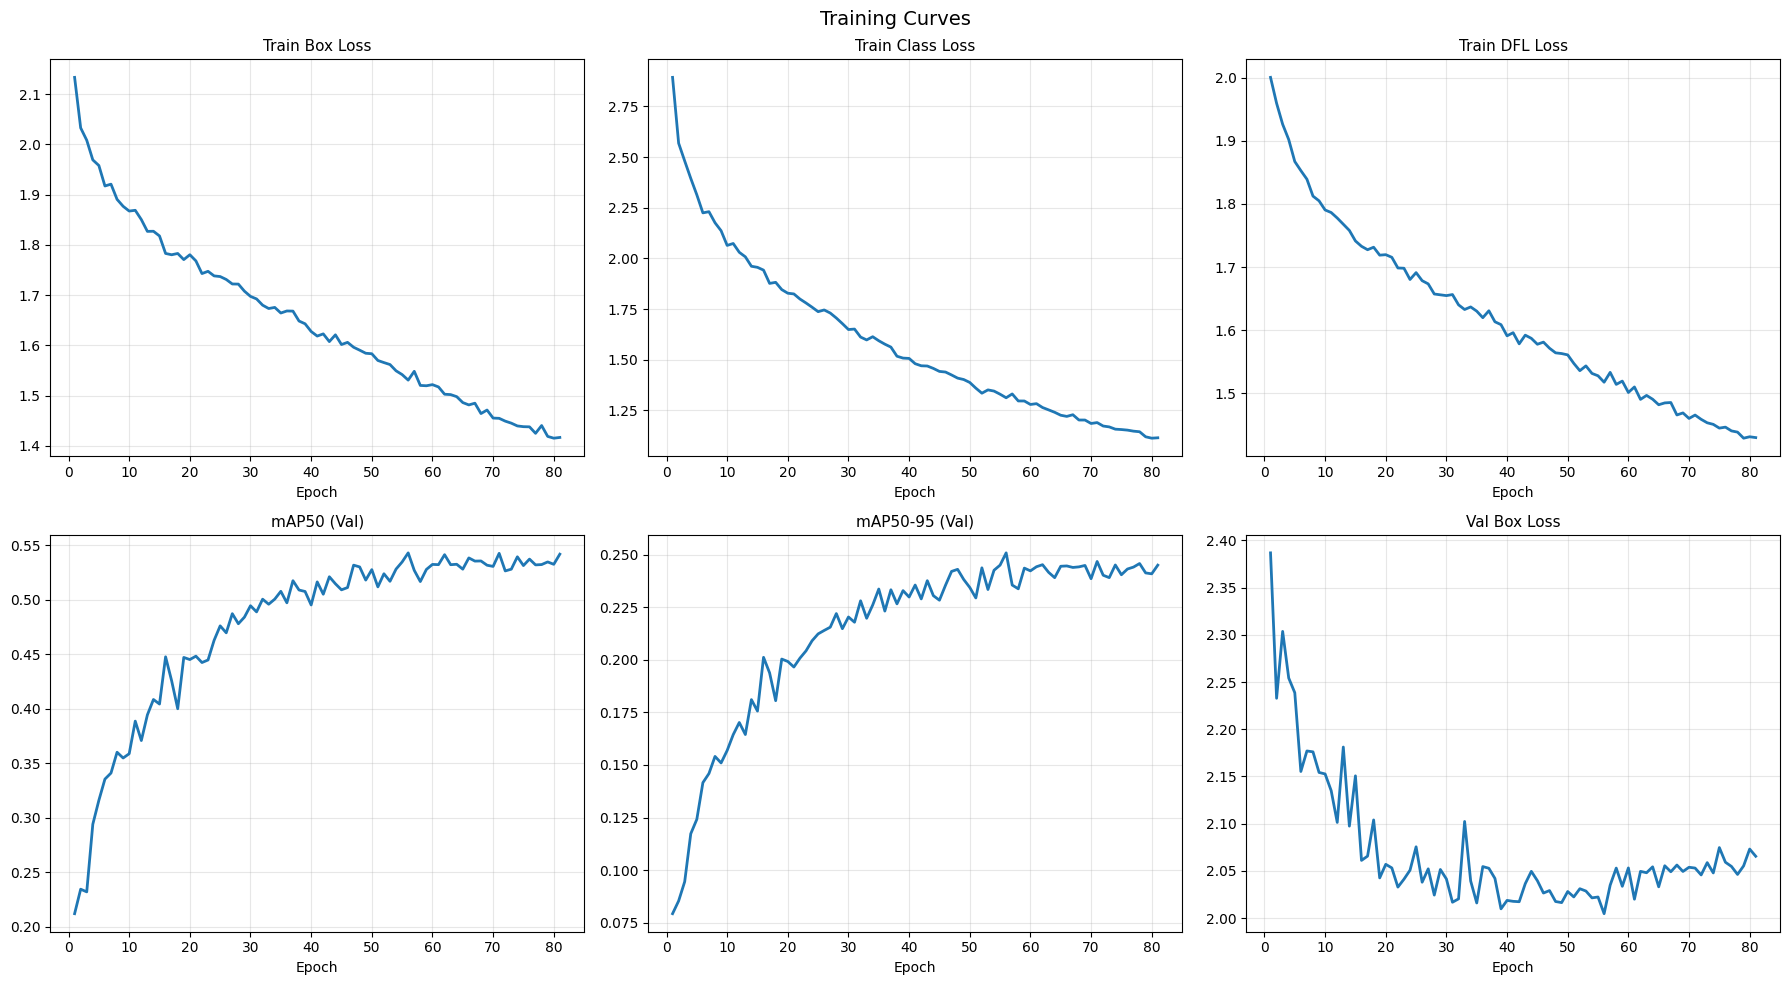

Saved: training_curves.png


In [20]:
# Plot training curves from results.csv
import pandas as pd

results_csv = os.path.join(TRAIN_DIR, 'results.csv')
if os.path.exists(results_csv):
    df = pd.read_csv(results_csv)
    df.columns = df.columns.str.strip()

    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    metrics = [
        ('train/box_loss',  'Train Box Loss',        axes[0][0]),
        ('train/cls_loss',  'Train Class Loss',      axes[0][1]),
        ('train/dfl_loss',  'Train DFL Loss',        axes[0][2]),
        ('metrics/mAP50(B)','mAP50 (Val)',           axes[1][0]),
        ('metrics/mAP50-95(B)', 'mAP50-95 (Val)',   axes[1][1]),
        ('val/box_loss',    'Val Box Loss',           axes[1][2]),
    ]

    for col, title, ax in metrics:
        if col in df.columns:
            ax.plot(df['epoch'], df[col], linewidth=2)
            ax.set_title(title, fontsize=11)
            ax.set_xlabel('Epoch')
            ax.grid(alpha=0.3)
        else:
            ax.set_title(f'{title} (N/A)')
            ax.axis('off')

    plt.suptitle('Training Curves', fontsize=14)
    plt.tight_layout()
    plt.savefig(f'{PLOTS_DIR}/training_curves.png', dpi=150, bbox_inches='tight')
    plt.show()
    print("Saved: training_curves.png")
else:
    print("results.csv not found — skipping curves plot.")

## ✅ Step 8: Run Predictions & Visualize Results

In [21]:
# Predict on test images
TEST_IMG_DIR    = split_info['test']['img_dir']
PRED_OUTPUT_DIR = f'{PLOTS_DIR}/predictions'

print(f"Running inference on: {TEST_IMG_DIR}")
pred_results = best_model.predict(
    source     = TEST_IMG_DIR,
    imgsz      = IMG_SIZE,
    conf       = 0.25,          # confidence threshold
    iou        = 0.45,          # NMS IoU threshold
    save       = True,
    save_txt   = True,
    save_conf  = True,
    project    = PRED_OUTPUT_DIR,
    name       = 'results',
    device     = DEVICE,
    verbose    = False,
)

print(f"\n✅ Predictions saved to: {PRED_OUTPUT_DIR}")

Running inference on: /kaggle/working/oral_dataset_balanced/test/images
Results saved to /kaggle/working/plots/predictions/results
369 labels saved to /kaggle/working/plots/predictions/results/labels

✅ Predictions saved to: /kaggle/working/plots/predictions


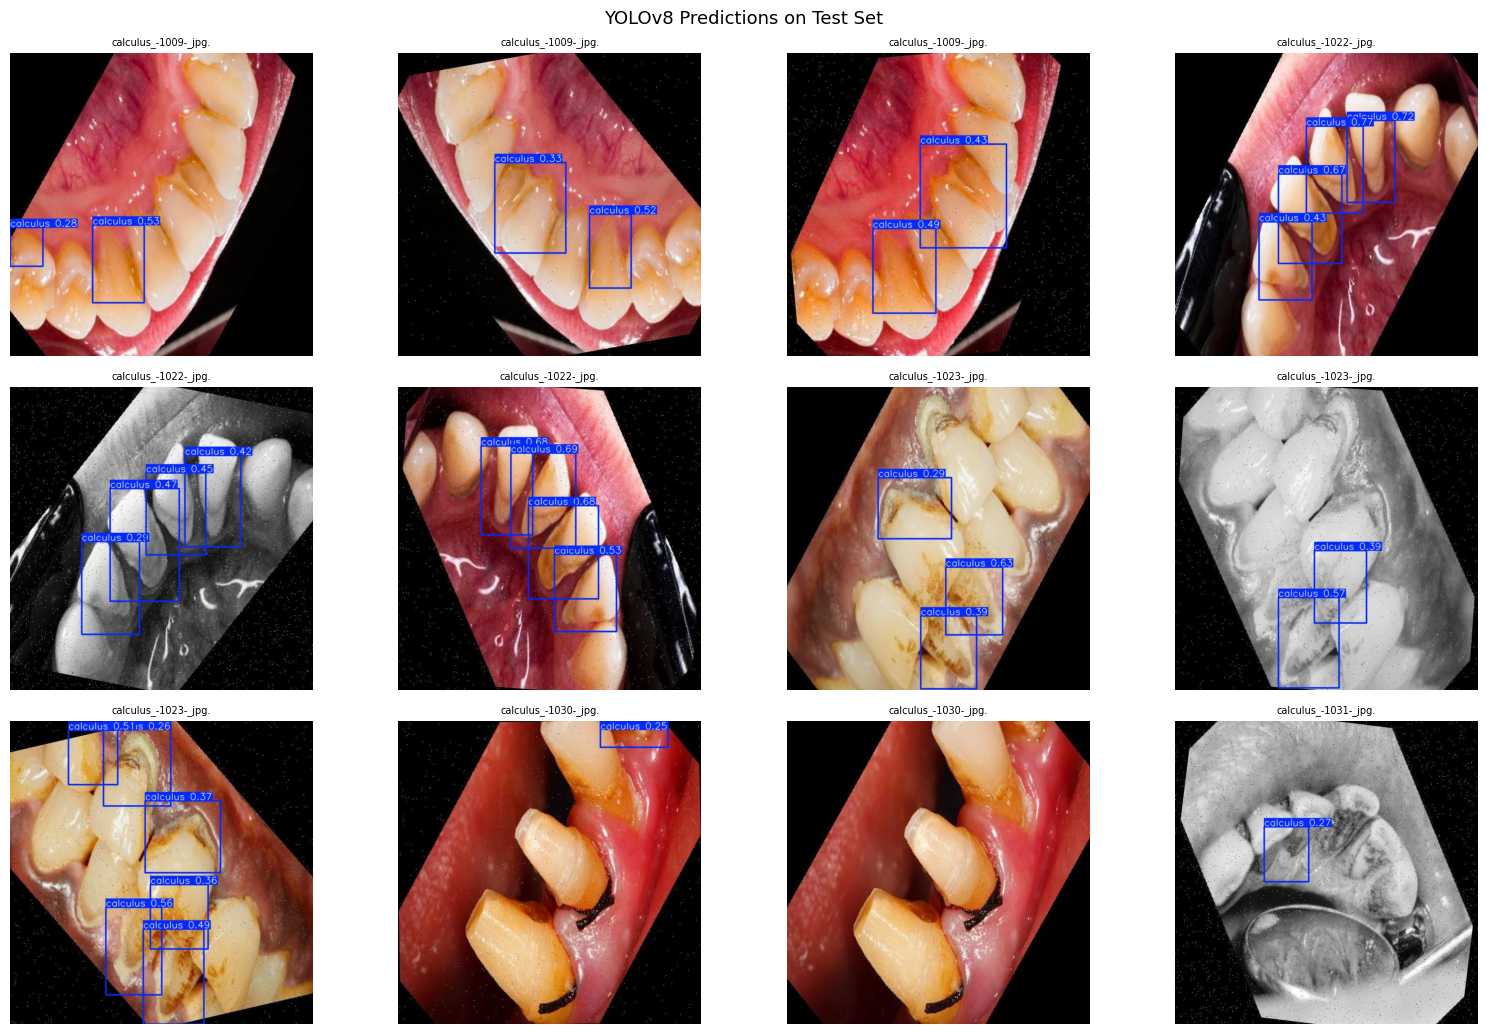

Saved: predictions_grid.png


In [ ]:
# Visualize 12 prediction results
pred_img_dir = os.path.join(PRED_OUTPUT_DIR, 'results')
pred_imgs = glob.glob(os.path.join(pred_img_dir, '*.jpg')) + \
            glob.glob(os.path.join(pred_img_dir, '*.png'))
pred_imgs = sorted(pred_imgs)[:12]

if pred_imgs:
    cols = 4
    rows = (len(pred_imgs) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 4, rows * 3.5))
    axes = axes.flatten()
    for i, p in enumerate(pred_imgs):
        img = Image.open(p)
        axes[i].imshow(img)
        axes[i].axis('off')
        axes[i].set_title(Path(p).stem[:20], fontsize=7)
    for j in range(len(pred_imgs), len(axes)):
        axes[j].axis('off')
    plt.suptitle('YOLOv8 Predictions on Test Set', fontsize=13)
    plt.tight_layout()
    plt.savefig(f'{PLOTS_DIR}/predictions_grid.png', dpi=120, bbox_inches='tight')
    plt.show()
    print("Saved: predictions_grid.png")
else:
    print("No predicted images found — check PRED_OUTPUT_DIR.")

In [ ]:
# ── Detection count by class
class_detect_counts = Counter()
for r in pred_results:
    if r.boxes is not None:
        for cls in r.boxes.cls.cpu().numpy():
            class_detect_counts[int(cls)] += 1

print("\n📊 Total Detections on Test Set (conf >= 0.25):")
print("-" * 35)
for i, name in enumerate(CLASS_NAMES):
    print(f"  {name:<15} : {class_detect_counts.get(i, 0):>5}")
print("-" * 35)
print(f"  {'TOTAL':<15} : {sum(class_detect_counts.values()):>5}")


📊 Total Detections on Test Set (conf >= 0.25):
-----------------------------------
  calculus        :   492
  cancer          :    12
  caries          :   331
  gingivitis      :   300
  ulcer           :   206
-----------------------------------
  TOTAL           :  1341


## ✅ Step 9: Export & Save Best Model

Download `/kaggle/working/final_results/best.pt` from the **Output** tab, replace `best.pt` in the project root, then restart the Flask server.

In [ ]:

SAVE_DIR = '/kaggle/working/final_results'
os.makedirs(SAVE_DIR, exist_ok=True)

# Copy weights
shutil.copy(BEST_WEIGHTS, f'{SAVE_DIR}/best.pt')

last_weights = os.path.join(TRAIN_DIR, 'weights', 'last.pt')
if os.path.exists(last_weights):
    shutil.copy(last_weights, f'{SAVE_DIR}/last.pt')

# Copy YOLO result files
for f in [
    'results.csv', 'confusion_matrix.png', 'PR_curve.png',
    'P_curve.png', 'R_curve.png', 'F1_curve.png',
    'val_batch0_pred.jpg'
]:
    src = os.path.join(TRAIN_DIR, f)
    if os.path.exists(src):
        shutil.copy(src, SAVE_DIR)

# Copy generated plots
for f in [
    'class_distribution.png',
    'training_curves.png',
    'predictions_grid.png',
    'samples_train.png'
]:
    src = f'{PLOTS_DIR}/{f}'
    if os.path.exists(src):
        shutil.copy(src, SAVE_DIR)

# Copy YAML
shutil.copy(YAML_PATH, SAVE_DIR)

# Show saved files
print(f"\n✅ Files saved to: {SAVE_DIR}\n")

for f in sorted(os.listdir(SAVE_DIR)):
    size = os.path.getsize(os.path.join(SAVE_DIR, f)) / 1024
    print(f"{f:<35} {size:>8.1f} KB")


✅ Files saved to: /kaggle/working/final_results

best.pt                              21998.7 KB
class_distribution.png                 101.0 KB
confusion_matrix.png                   168.0 KB
data.yaml                                0.3 KB
last.pt                              21998.7 KB
predictions_grid.png                  2191.7 KB
results.csv                             10.1 KB
samples_train.png                     1522.2 KB
training_curves.png                    236.3 KB
val_batch0_pred.jpg                    339.0 KB


## ✅ Step 10: Final Summary

In [ ]:
print(f"""
============================================================
🦷 DENTAL YOLOV8 — TRAINING SUMMARY
============================================================

Model          : {MODEL_VARIANT}
Classes        : {', '.join(CLASS_NAMES)}

Train images   : {split_info['train']['images']:,}
Valid images   : {split_info['valid']['images']:,}
Test images    : {split_info['test']['images']:,}

Epochs trained : {EPOCHS} (with early stopping)
Image size     : {IMG_SIZE}

Best weights   : {BEST_WEIGHTS}

------------------------------------------------------------

Val  mAP50     : {val_results.box.map50:.4f}
Val  mAP50-95  : {val_results.box.map:.4f}

Test mAP50     : {test_results.box.map50:.4f}
Test mAP50-95  : {test_results.box.map:.4f}

------------------------------------------------------------

Results saved  : {SAVE_DIR}

============================================================
✅ Done! Your trained model is ready.
============================================================
""")


🦷 DENTAL YOLOV8 — TRAINING SUMMARY

Model          : yolov8s.pt
Classes        : calculus, cancer, caries, gingivitis, ulcer

Train images   : 3,797
Valid images   : 696
Test images    : 503

Epochs trained : 100 (with early stopping)
Image size     : 640

Best weights   : /kaggle/working/oral_runs/yolov8s_balanced_v2/weights/best.pt

------------------------------------------------------------

Val  mAP50     : 0.5428
Val  mAP50-95  : 0.2514

Test mAP50     : 0.5679
Test mAP50-95  : 0.2671

------------------------------------------------------------

Results saved  : /kaggle/working/final_results

✅ Done! Your trained model is ready.



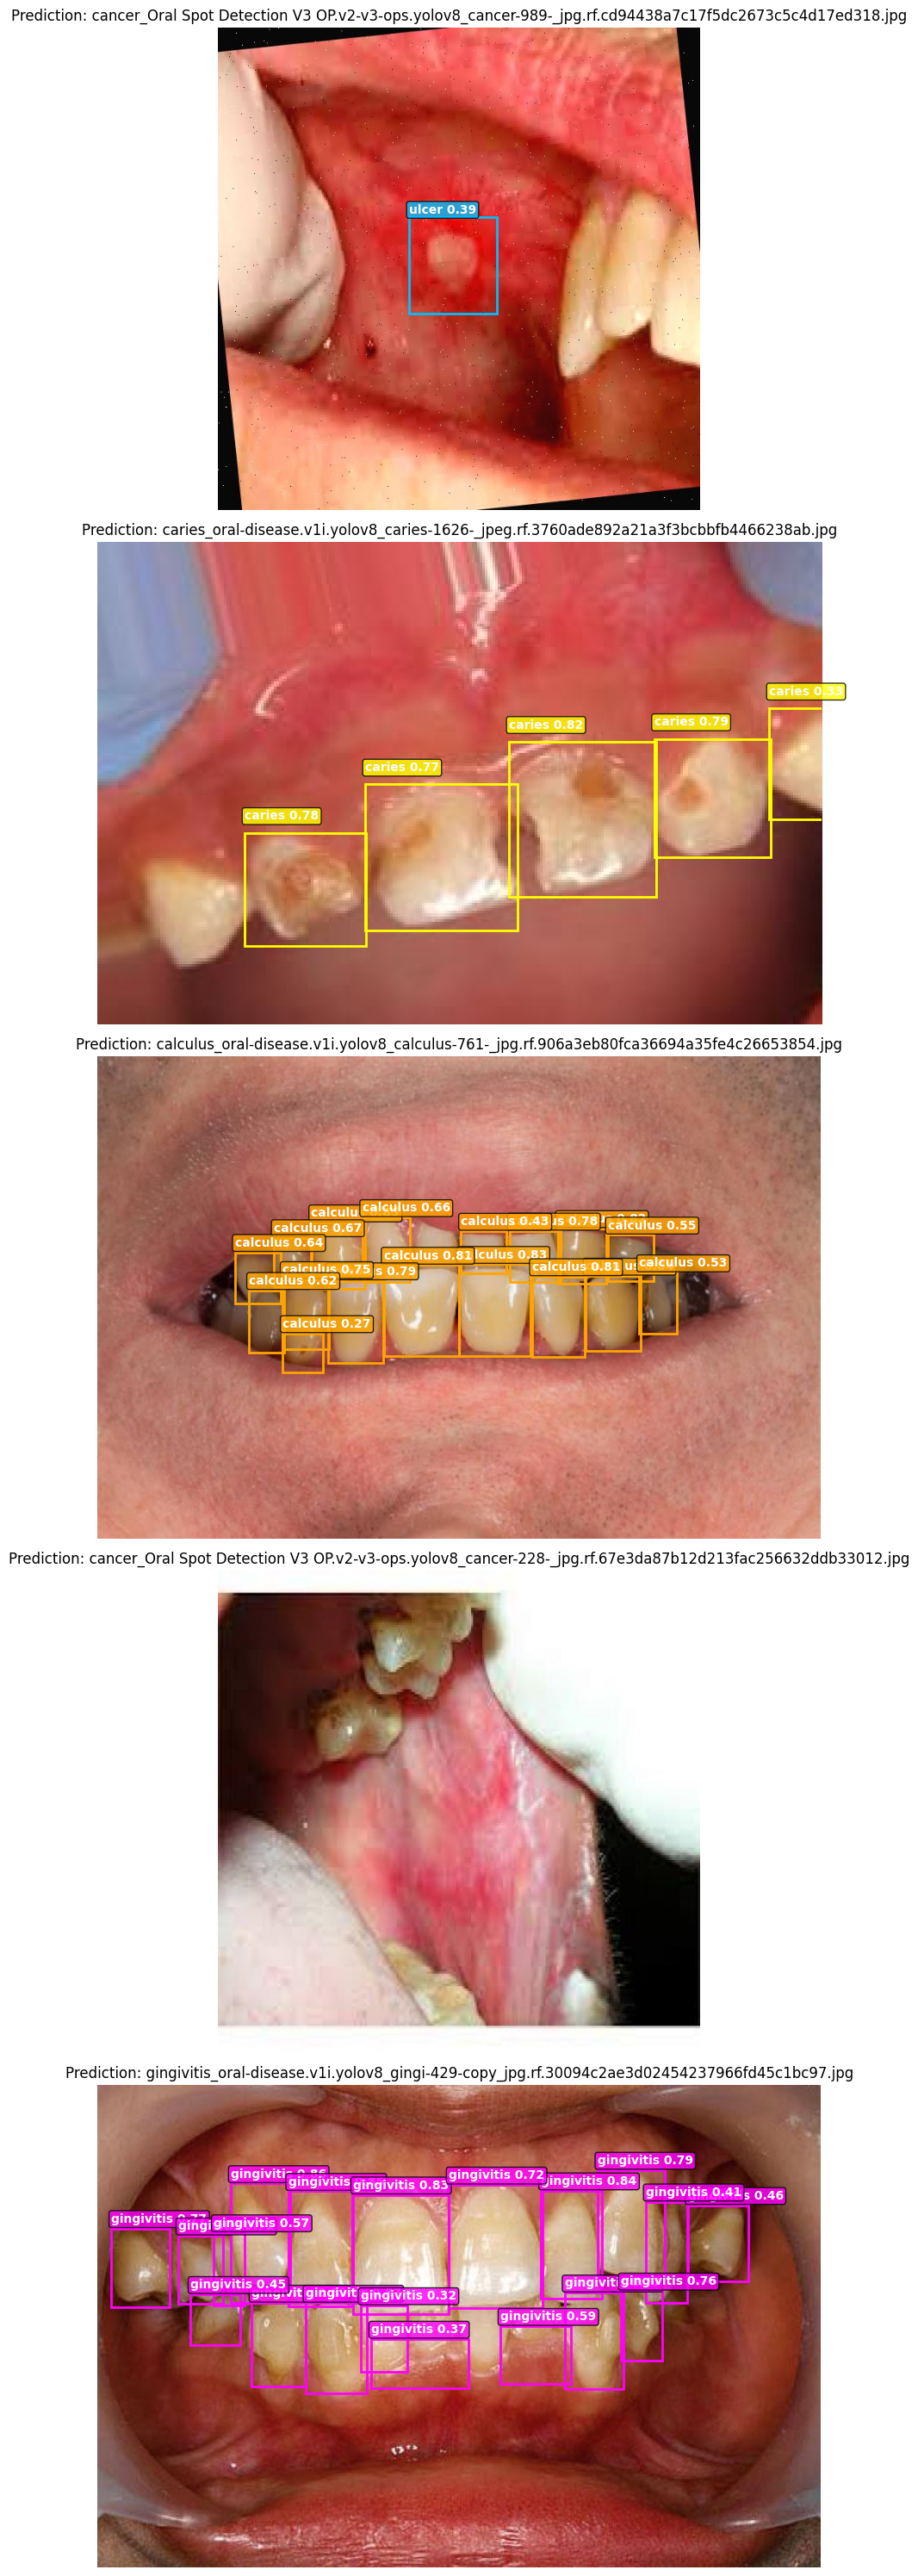


✅ Test predictions saved to /kaggle/working/final_results/test_predictions.png


In [ ]:
# =========================================================
# TEST MODEL ON RANDOM TEST IMAGES (COMPACT)
# =========================================================

import os, random
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Config
TEST_IMAGES_DIR = split_info['test']['img_dir']
SAMPLE_SIZE = 5

# Get random images
all_images = [f for f in os.listdir(TEST_IMAGES_DIR) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
sample_images = random.sample(all_images, min(SAMPLE_SIZE, len(all_images)))

# Predict and plot
fig, axes = plt.subplots(len(sample_images), 1, figsize=(10, 6 * len(sample_images)))
if len(sample_images) == 1: axes = [axes]

for ax, img_name in zip(axes, sample_images):
    result = best_model.predict(source=os.path.join(TEST_IMAGES_DIR, img_name), conf=0.25, iou=0.45, imgsz=IMG_SIZE, verbose=False)[0]
    img = Image.open(os.path.join(TEST_IMAGES_DIR, img_name)).convert('RGB')
    ax.imshow(img)
    
    if result.boxes:
        for box in result.boxes:
            x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()
            cls, conf = int(box.cls[0].item()), float(box.conf[0].item())
            ax.add_patch(patches.Rectangle((x1, y1), x2-x1, y2-y1, linewidth=2, edgecolor=COLORS[cls], facecolor='none'))
            ax.text(x1, max(y1-5, 0), f'{CLASS_NAMES[cls]} {conf:.2f}', color='white', fontsize=10, weight='bold',
                   bbox=dict(boxstyle='round,pad=0.2', fc=COLORS[cls], alpha=0.8))
    
    ax.set_title(f'Prediction: {img_name}', fontsize=12)
    ax.axis('off')

plt.tight_layout()
plt.savefig('/kaggle/working/final_results/test_predictions.png', dpi=150, bbox_inches='tight')
plt.show()
print("\n✅ Test predictions saved to /kaggle/working/final_results/test_predictions.png")